# Finite-monitor imaging with a 3 × 3 phase diffractive grating

A phase grating splits an incident beam into multiple diffraction orders․ With an extended, spatially incoherent source, each order can form a source image on a monitor plane. In this example‚ we first create a 3x3 array phase grating that will generate nine nearly equal diffraction orders and the investigate the effects of wide-angle propagation on images with incoherent sources․


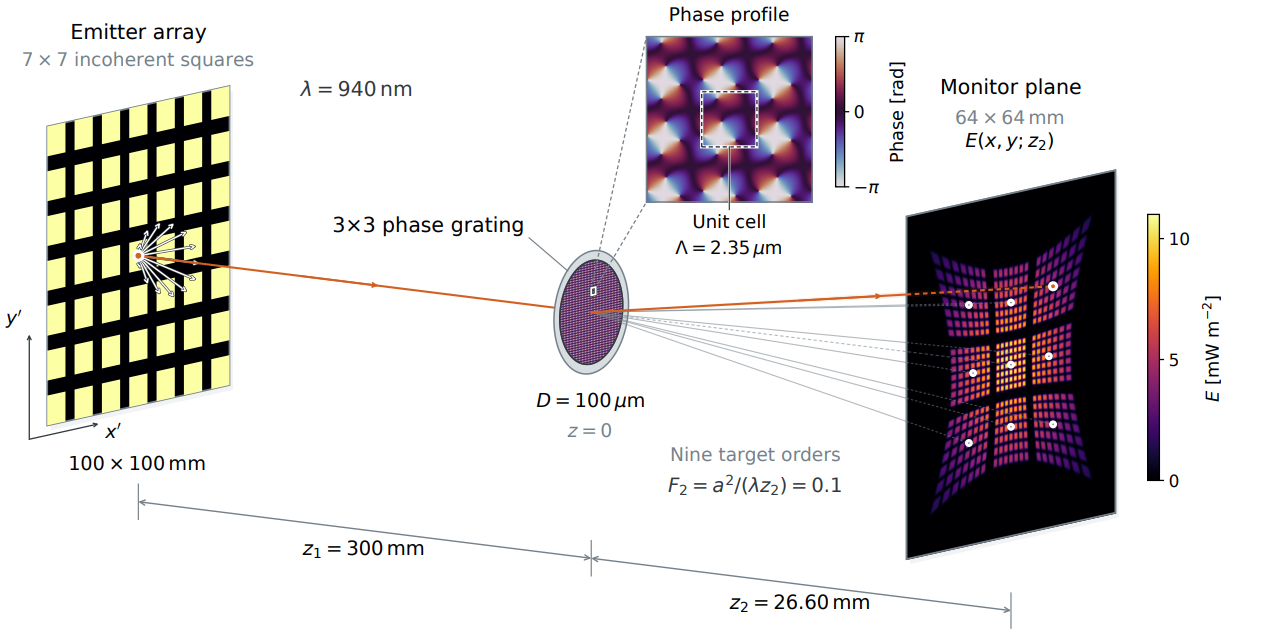


## 1. Design the 3x3 phase grating

We first perform the grating design using `phase_grating_design`, which searches a periodic phase profile using an Adam optimizer.
`target(m, n)` selects equal relative powers for $m,n\in\{-1,0,1\}$. The Adam optimizer first searches a $128\times128$ phase cell, then refines it on a $512\times512$ grid. The larger refinement weight puts more emphasis on equal powers, so the two loss curves use different weights.

For the unit cell, the we write the Fourier-coefficient power fractions as $I_{mn}=|b_{mn}|^2$. We report the selected-order efficiency $\eta_{\mathrm{cell}}=\sum_{m,n=-1}^{1}I_{mn}$ and nonuniformity $U_{\mathrm{cell}}=(I_{\max}-I_{\min})/(I_{\max}+I_{\min})$. At an incident irradiance of $1\,\mathrm{W\,m^{-2}}$, dividing each order's power by the cell area gives its power fraction.




In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import MonochromaticField, IncoherentLightSimulation
from diffractsim import ApertureFromFunction, phase_grating_design, mm, um, nm
from diffractsim.util.backend_functions import backend as bd
from diffractsim.util.phase_grating import periodic_phase_grating
from diffractsim.util.image_handling import load_image, load_image_as_function

plt.rcParams["figure.dpi"] = 150

Efficiency: 93.948260%; nonuniformity: 0.315820%


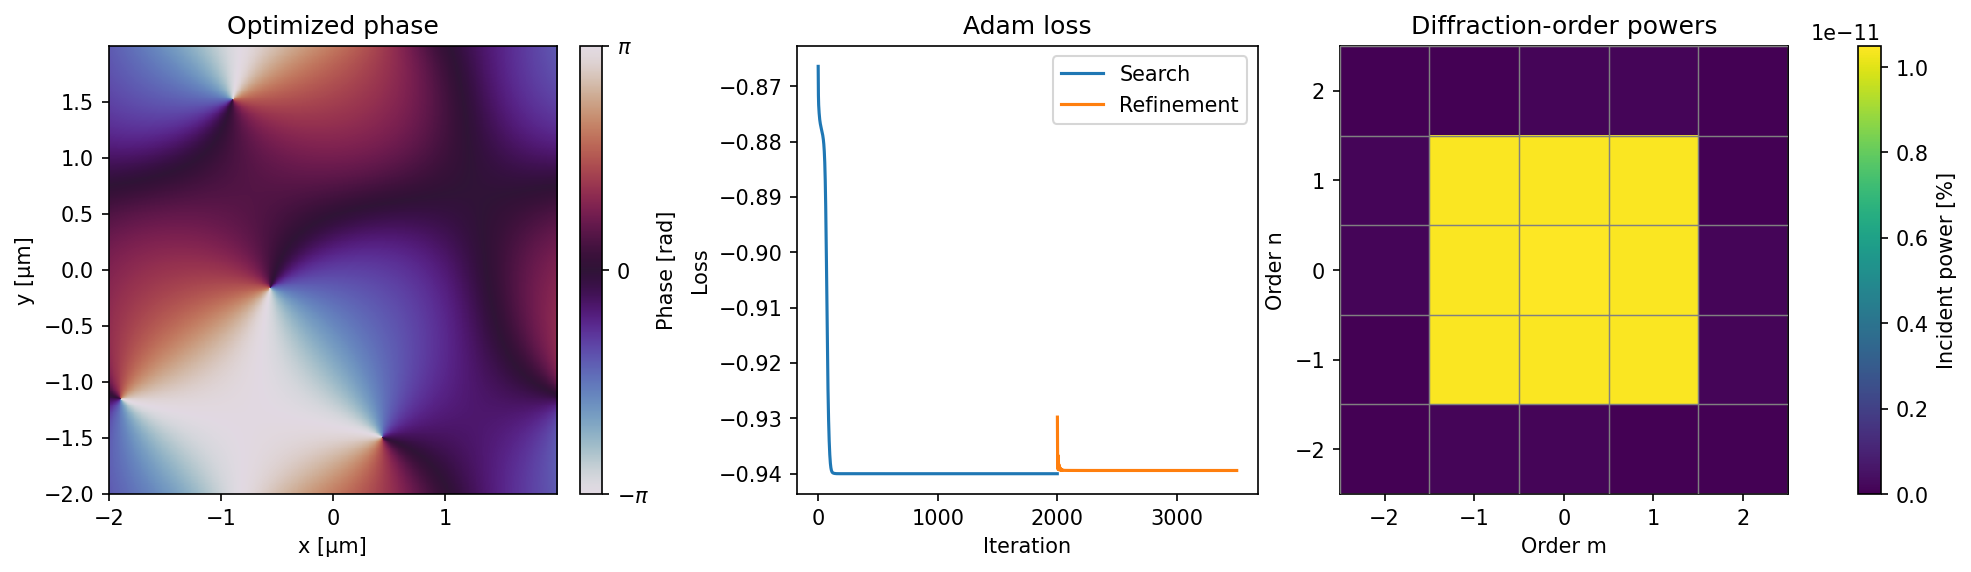

In [2]:
##########################
# Design the phase grating
##########################


def target(m, n):
    return (abs(m) <= 1) & (abs(n) <= 1)

phase, search_history = phase_grating_design(target, Nx=128, seed=2,iterations=2000, learning_rate=0.03, weight=0.5)
phase_cell, fine_history = phase_grating_design(target, Nx=512, initial_phase=phase, iterations=1500, learning_rate=0.01, weight=10)

# Evaluate the design as one physical unit cell, illuminated at 1 W/m².
wavelength, period = 1*um, 4*um
Ny, Nx = phase_cell.shape
grating_field = MonochromaticField(wavelength, period, period, Nx, Ny, intensity=1)
grating_field.E = bd.exp(1j*phase_cell)


####################
# Print design metrics
####################

order_m, order_n, power = grating_field.get_modes_power()
order_power = np.asarray(power)/period**2
selected_power = order_power[np.asarray(target(order_m, order_n)) > 0]
efficiency = selected_power.sum()
nonuniformity = np.ptp(selected_power)/(selected_power.max()+selected_power.min())
print(f"Efficiency: {100*efficiency:.6f}%; nonuniformity: {100*nonuniformity:.6f}%")

####################
# Visualization
####################

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained")
grating_field.plot_phase(grating_field.E, ax=axes[0], cmap="twilight",units=um, text="Optimized phase")
axes[1].plot(search_history, label="Search")
axes[1].plot(len(search_history)+np.arange(len(fine_history)), fine_history, label="Refinement")
axes[1].set(title="Adam loss", xlabel="Iteration", ylabel="Loss")
axes[1].legend()
grating_field.plot_grating_modes(100*order_power, ax=axes[2],xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), colorbar_label="Incident power [%]")
plt.show()

## Example with the designed grating: coherent and collimated Gaussian illumination of the 3x3 phase grating:

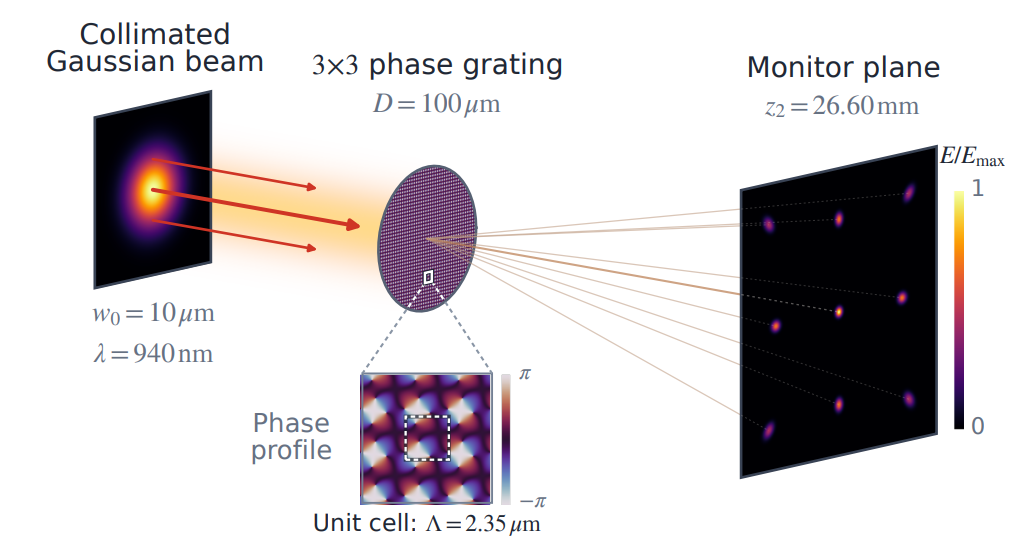

## 2. Illuminate the circular phase pupil with a square-array of incoherent emitters

We now repeat the optimized phase $\phi$ inside a pupil of radius $a=50\,\mu\mathrm{m}$:

$$
\mathscr{P}(\xi,\eta)=\mathbf{1}_{\xi^2+\eta^2\le a^2}
\exp\!\left[i\phi\!\left(\frac{\xi}{\Lambda}\bmod 1,\frac{\eta}{\Lambda}\bmod 1\right)\right].
$$

The cell is rescaled to $\Lambda=2.35\,\mu\mathrm{m}$ at $\lambda=940\,\mathrm{nm}$, preserving its Fourier-coefficient powers. Periodic cubic interpolation keeps the pupil differentiable with respect to the phase samples.

The source lies at $z=-z_1$, with $z_1=300\,\mathrm{mm}$. Its $7\times7$ squares are $10\,\mathrm{mm}$ wide, spaced by $15\,\mathrm{mm}$, and emit with radiance $L_0=10^4\,\mathrm{W\,m^{-2}\,sr^{-1}}$. The monitor distance follows from $F_2=a^2/(\lambda z_2)=0.1$, giving $z_2\simeq26.60\,\mathrm{mm}$.

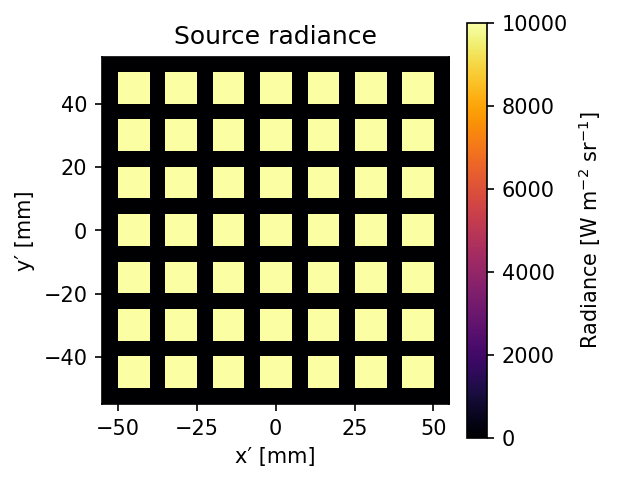

<Axes: title={'center': 'Source radiance'}, xlabel='x′ [mm]', ylabel='y′ [mm]'>

In [6]:
# Set up and plot the incoherent source array.
wavelength, z1 = 940*nm, 300*mm
source_pitch, square_side, source_count, L0 = 15*mm, 10*mm, 7, 1e4
pupil_samples, pupil_width = 2048, 110*um  # Increase samples to refine the pupil.

##############################################################
# sim_grating contains the simulation object we are goint to use
##############################################################

sim_grating = IncoherentLightSimulation(wavelength, pupil_width, pupil_width,pupil_samples, pupil_samples)


##############################################################
# set up the source (incoherent emitter array)
##############################################################


def square_source(x, y):
    """Return the plane radiance of the finite array of emitting squares."""
    ix, iy = bd.round(x/source_pitch), bd.round(y/source_pitch)
    inside_array = (abs(ix) <= (source_count-1)/2) & (abs(iy) <= (source_count-1)/2)
    inside_square = (abs(x-source_pitch*ix) <= square_side/2) & (abs(y-source_pitch*iy) <= square_side/2)
    return L0*inside_array*inside_square

sim_grating.set_illumination_from_plane(square_source, distance=z1, paraxial=False,angular_samples=2048, angular_limit=2.0,source_subpixels=4)  # Use 1 to disable averaging.
sim_grating.plot_source_radiance(figsize=(4, 3.6), xlim=(-55*mm, 55*mm), ylim=(-55*mm, 55*mm),units=mm, samples=512, title="Source radiance")


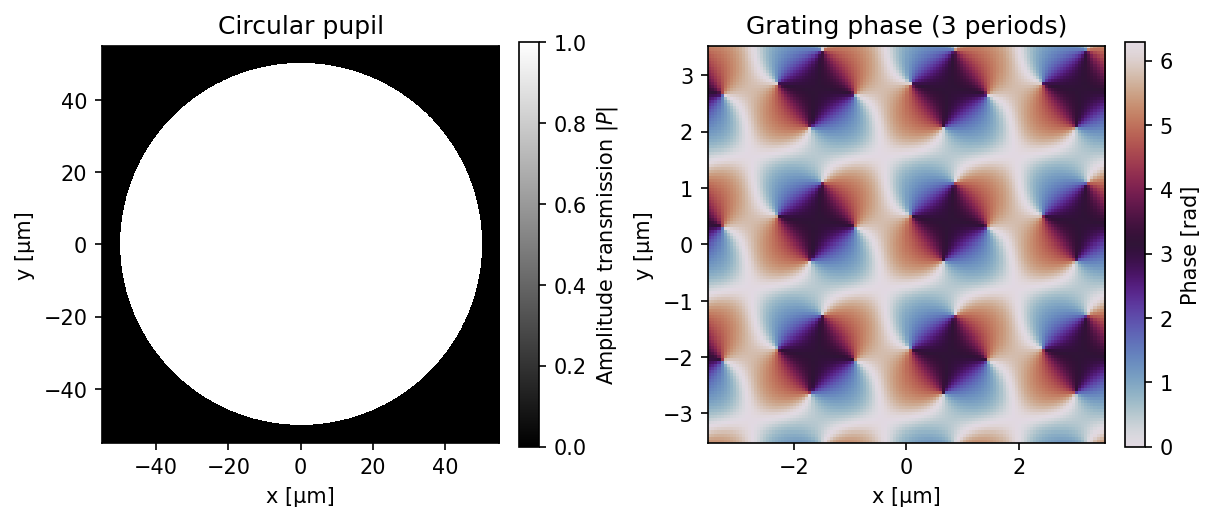

Monitor distance: 26.5957 mm


In [7]:
# Set up and plot the grating and circular aperture.
radius, period, F2 = 50*um, 2.35*um, 0.10
z2 = radius**2/(wavelength*F2)

def grating_pupil(phase):
    """Repeat the designed phase cell and clip it to the circular pupil."""
    transmission = periodic_phase_grating(phase, sim_grating.x, sim_grating.y, period)
    inside = sim_grating.xx**2+sim_grating.yy**2 <= radius**2
    return inside*transmission


pupil = grating_pupil(bd.asarray(phase_cell))
aperture_grating = ApertureFromFunction(lambda x, y, wl: pupil)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")
sim_grating.plot_aperture(pupil, units=um, ax=axes[0], title="Circular pupil")
sim_grating.plot_aperture(pupil, phase=True, units=um, ax=axes[1],xlim=(-1.5*period, 1.5*period), ylim=(-1.5*period, 1.5*period),title="Grating phase (3 periods)")
plt.show()

print(f"Monitor distance: {z2/mm:.4f} mm")

## 3. Form the square-array emitter

`grating_model` applies the pupil and propagates to the monitor using the angular-spectrum method. The simulator includes the common incident curvature through $Q_{z_1}(\mathbf r)=\mathscr{P}(\mathbf r)\exp[i\pi|\mathbf r|^2/(\lambda z_1)]$. Its coherent intensity response is $H^{\mathrm{mon}}_{z_1,z_2}=|\mathcal{P}_{z_2}\{Q_{z_1}\}|^2$.

`get_irradiance` combines this one response with the angular source radiance $L_{\mathrm{in}}$ using the finite-distance approximation in Eq. (24):

$$
E(x,y;z_1,z_2)\simeq\frac{z_2^2}{\rho^4}
\left[L_{\mathrm{in}}(-\alpha,-\beta)\otimes
\left[\frac{z_2^2}{c^4}H^{\mathrm{mon}}_{z_1,z_2}
\!\left(\frac{z_2\alpha}{c},\frac{z_2\beta}{c}\right)\right]\right]_{(\alpha,\beta)=(x,y)/\rho}.
\tag{24}
$$



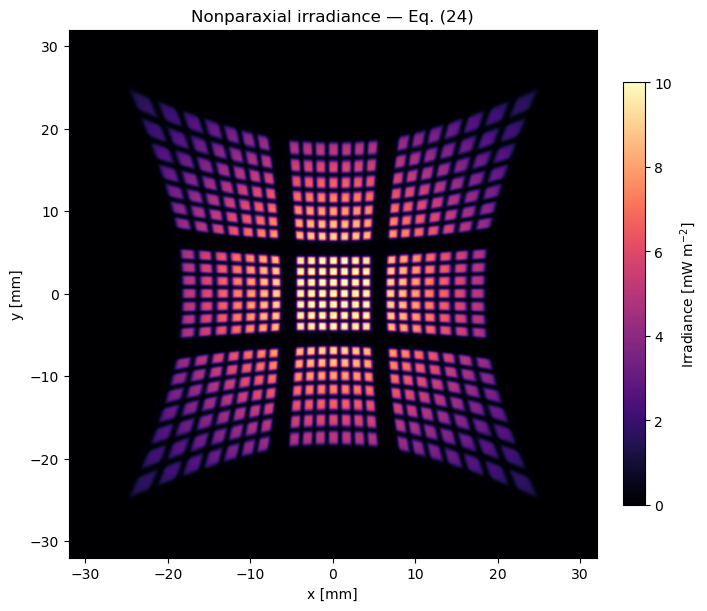

<Axes: title={'center': 'Nonparaxial irradiance — Eq. (24)'}, xlabel='x [mm]', ylabel='y [mm]'>

In [4]:
# 3. Fig. 5(c): the complete coherent model, followed by Eq. (24).
def optical_setup(F, z):
    """Apply the grating and propagate with the angular-spectrum method."""
    F = F.add(aperture_grating)
    F = F.zoom_propagate(z, x_interval=[-32*mm, 32*mm], y_interval=[-32*mm, 32*mm], model="Fresnel", sampling="angular")
    return F

x, y, E = sim_grating.get_irradiance(optical_setup, z2)
sim_grating.plot_irradiance(E, cmap="magma", irradiance_units=1e-3, vmax=10,text="Nonparaxial irradiance — Eq. (24)")

### Check the square-array image with full RS propagation

We now evaluate the same source and pupil with the two-leg Rayleigh–Sommerfeld integral, Eq. (25), to reproduce the reference in Fig. 5(d). Each emitter keeps its own spherical incident field, and the outgoing field uses the full RS kernel:

$$
E_{\mathrm{RS}}(x,y)=\iint_{\mathcal D}L_{\mathrm{in}}(\alpha',\beta')
\left|\iint\mathscr P(\xi,\eta)\,A_{\alpha',\beta'}(\xi,\eta)
\,h_{z_2}(x-\xi,y-\eta)\,\mathrm d\xi\,\mathrm d\eta\right|^2
\mathrm d\alpha'\,\mathrm d\beta'.
$$

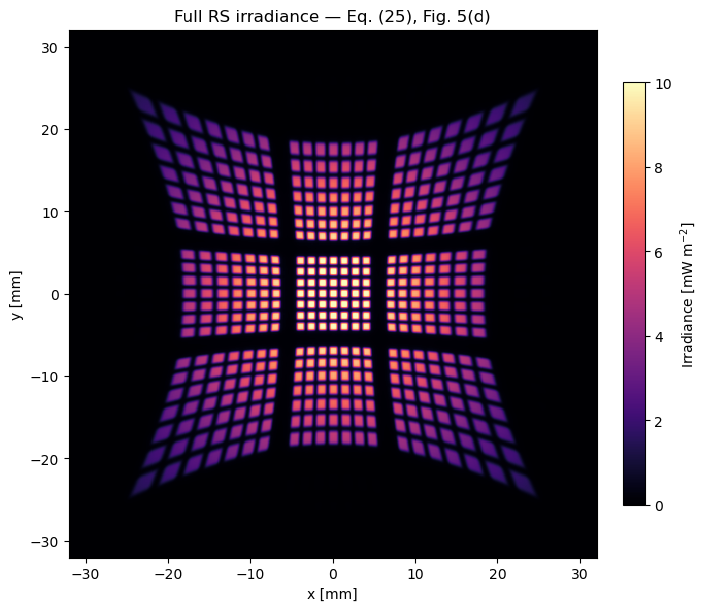

<Axes: title={'center': 'Full RS irradiance — Eq. (25), Fig. 5(d)'}, xlabel='x [mm]', ylabel='y [mm]'>

In [5]:
# 3a. Fig. 5(d): full RS reference for the same source and pupil.
x_rs, y_rs, E_rs = sim_grating.get_irradiance_rs(optical_setup, z2,
    Nx_mon=513, Ny_mon=513)
sim_grating.plot_irradiance(E_rs, cmap="magma", irradiance_units=1e-3, vmax=10,
    text="Full RS irradiance — Eq. (25), Fig. 5(d)")


## 4. Replacing the square emitters with the USAF source


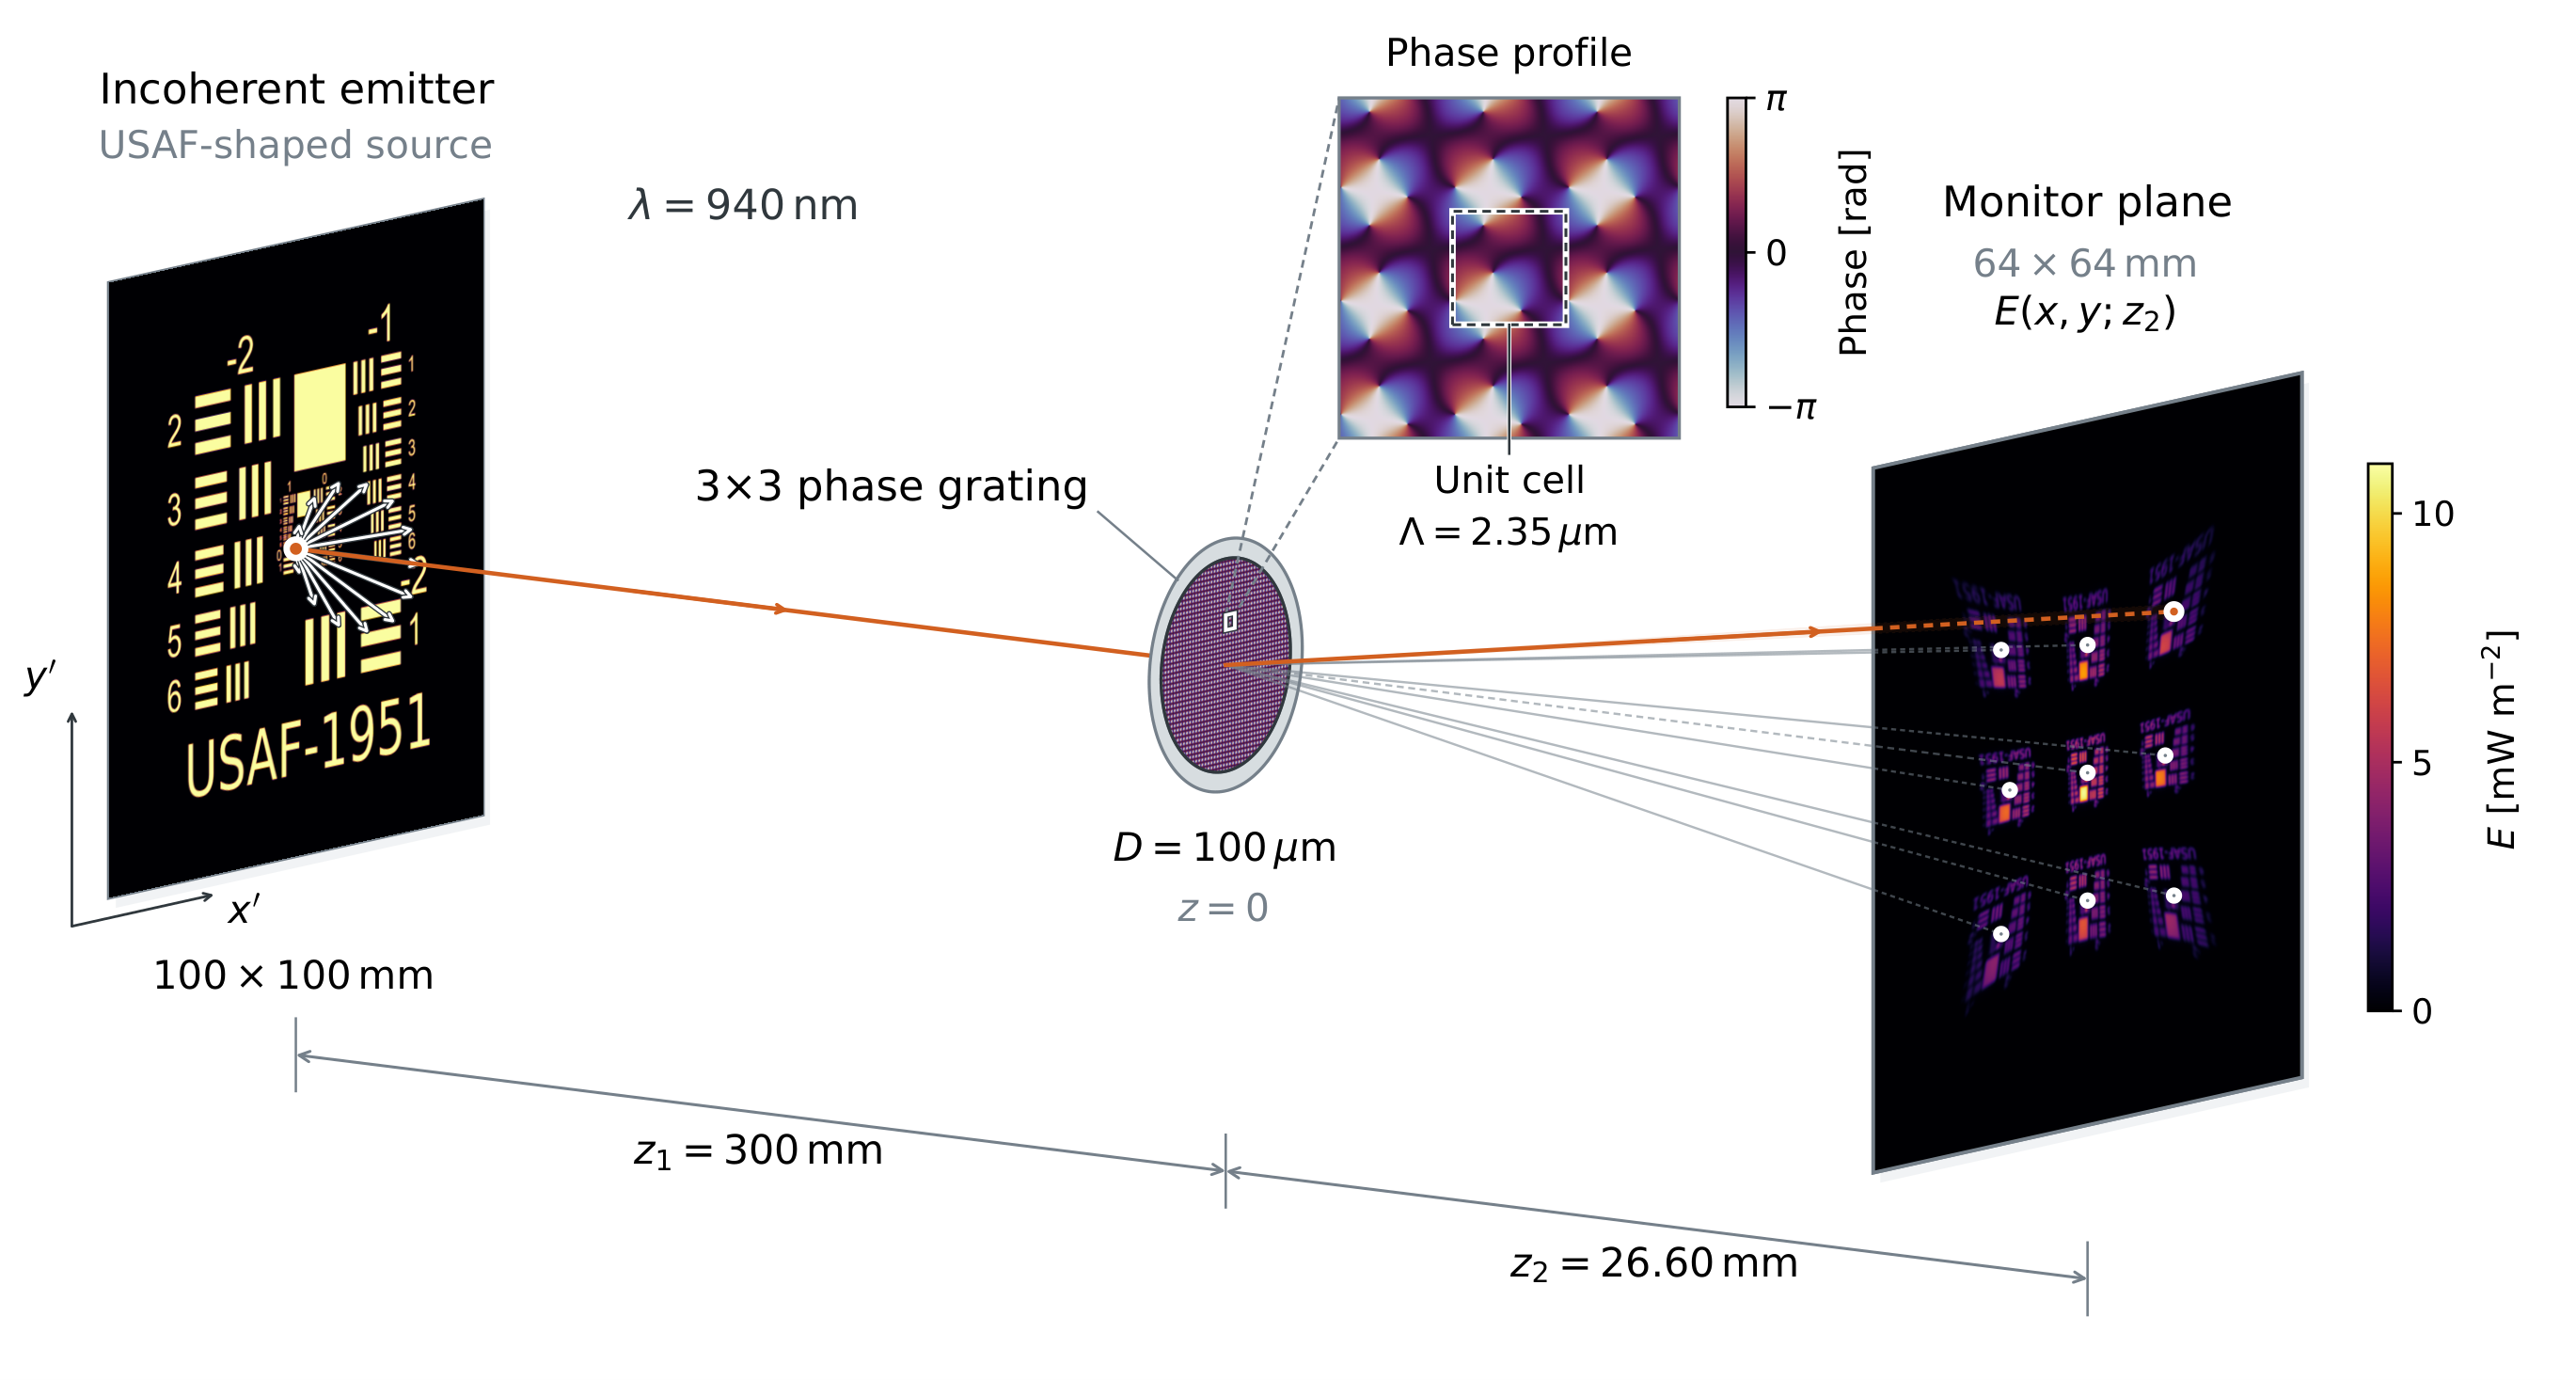

In this example, we just  keep the grating, pupil and distances fixed and change only the source radiance $L_0(x',y')$. The USAF pattern fills a $100\times100\,\mathrm{mm}$ source plane; `invert=True` turns its dark markings into emitting features, with a maximum radiance of $10^4\,\mathrm{W\,m^{-2}\,sr^{-1}}$ and zero outside the image.

`source_subpixels` averages the source within each angular sample to resolve its fine features. Set it to `1` for direct sampling.

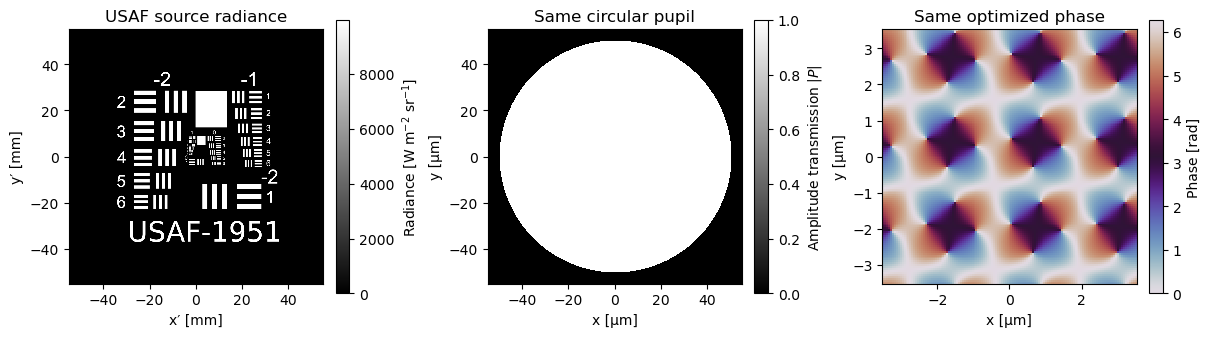

In [6]:
# 4. Fig. 5(f): the USAF source, with the same grating and distances.
usaf_width, usaf_radiance = 100*mm, 1e4
usaf_image = load_image_as_function("USAF_test_inv.png", invert=True,
    x_interval=(-usaf_width/2, usaf_width/2),
    y_interval=(-usaf_width/2, usaf_width/2),
    method="nearest")

def usaf_source(x, y):
    return usaf_radiance*usaf_image(x, y)

sim_usaf = IncoherentLightSimulation(wavelength, pupil_width, pupil_width,pupil_samples, pupil_samples)
sim_usaf.set_illumination_from_plane(usaf_source, distance=z1, paraxial=False,angular_samples=2048, angular_limit=2.0,
                                     source_subpixels=8)  # Use 1 to disable averaging.

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
sim_usaf.plot_illumination_plane(xlim=(-55*mm, 55*mm), ylim=(-55*mm, 55*mm),units=mm, samples=1100, ax=axes[0], cmap="gray", title="USAF source radiance")
sim_usaf.plot_aperture(pupil, units=um, ax=axes[1], title="Same circular pupil")
sim_usaf.plot_aperture(pupil, phase=True, units=um, ax=axes[2],xlim=(-1.5*period, 1.5*period), ylim=(-1.5*period, 1.5*period),
                       title="Same optimized phase")
plt.show()

## 5. Inspect the USAF images on the same monitor

The same `grating_model` now forms nine USAF images. Their positions follow the grating relation in Eq. (28):

$$
(\alpha_{mn},\beta_{mn})=\frac{\lambda}{\Lambda}(m,n)-(\alpha',\beta'),
\qquad
(x_{mn},y_{mn})=\frac{z_2(\alpha_{mn},\beta_{mn})}{\sqrt{1-\alpha_{mn}^2-\beta_{mn}^2}}.
\tag{28}
$$

The primed direction cosines identify a source point. The central image is inverted; the off-axis images stretch and bend as directions map onto the flat monitor. Both source examples use the same $0$–$10\,\mathrm{mW\,m^{-2}}$ colour scale, so their irradiance variation remains visible.

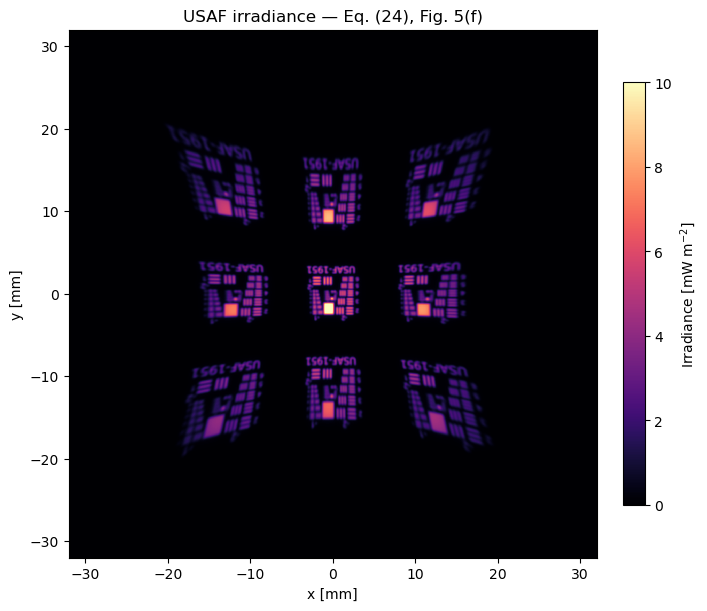

<Axes: title={'center': 'USAF irradiance — Eq. (24), Fig. 5(f)'}, xlabel='x [mm]', ylabel='y [mm]'>

In [7]:
# 5. Fig. 5(f): simulate Eq. (24), then plot in mW/m².
x_usaf, y_usaf, E_usaf = sim_usaf.get_irradiance(optical_setup, z2)
sim_usaf.plot_irradiance(E_usaf, cmap="magma", irradiance_units=1e-3, vmax=10,text="USAF irradiance — Eq. (24), Fig. 5(f)")


# Paper results verification

## 6. Reproduce Fig. 5(b–g)

We now compare the three models on one monitor, using the sources and phase pupil defined above. Separate simulation objects keep the earlier examples unchanged. Use the updated `vendor` folder supplied with the Fig. 5 reproduction bundle for this comparison; the RS implementation is unchanged.

As in Supplement S5.1, Eqs. (8) and (24) use the same axial coherent response
$H^{\mathrm{mon}}_{z_1,z_2}=|\mathcal P_{z_2}\{Q_{z_1}\}|^2$,
with $Q_{z_1}=\mathscr P\exp[i\pi(\xi^2+\eta^2)/(\lambda z_1)]$.
We calculate it with `model="ASM", sampling="angular"`.
The `paraxial` source setting selects how the source contributions are combined, rather than the coherent propagator.


In [8]:
# Fig. 5: one pupil, one monitor and separate comparison simulations.
fig5_halfwidth, fig5_samples = 32*mm, 513  # Use 1025 for a finer monitor grid.
fig5_angular_samples = 2048
fig5_source_order, fig5_monitor_order = 3, 9
fig5_source_halfwidth = ((source_count-1)*source_pitch+square_side)/2

def fig5_simulation(source, halfwidth, subpixels=4, paraxial=False):
    """Set up one source without changing the simulations above."""
    comparison = IncoherentLightSimulation(wavelength, pupil_width, pupil_width,
                                           pupil_samples, pupil_samples)
    limit = halfwidth/np.hypot(z1, halfwidth)
    comparison.set_illumination_from_plane(source, z1, paraxial=paraxial,
        angular_samples=fig5_angular_samples, angular_limit=2.0,
        source_subpixels=subpixels, source_bounds=(-limit, limit, -limit, limit))
    return comparison

def fig5_optics(F, z, halfwidth=fig5_halfwidth, samples=fig5_samples):
    """Apply the existing phase grating and propagate to a square monitor."""
    return F.add(aperture_grating).zoom_propagate(z,
        [-halfwidth, halfwidth], [-halfwidth, halfwidth],
        Nx_mon=samples, Ny_mon=samples, model="ASM", sampling="angular")

def fig5_paraxial_image(source, halfwidth):
    """Evaluate Eq. (8), retaining source shifts beyond the displayed edges."""
    comparison = fig5_simulation(source, halfwidth, paraxial=True)
    step = 2*fig5_halfwidth/(fig5_samples-1)
    margin = int(np.ceil((z2/z1)*halfwidth/step))+4
    def extended_monitor(F, z):
        return fig5_optics(F, z, fig5_halfwidth+margin*step,
                           fig5_samples+2*margin)
    x, y, E = comparison.get_irradiance(extended_monitor, z2)
    keep = slice(margin, -margin)
    return x[keep], y[keep], E[keep, keep]

### Square emitters: panels (b–d)

Equation (8) shifts one coherent response across the monitor. Equation (24) instead combines the source and response in direction-cosine coordinates, then maps the result onto the flat monitor. This retains the stretching and irradiance fall-off of the off-axis images.

The RS reference in Eq. (25) keeps each emitter's spherical incident field and the full outgoing kernel before adding intensities. `source_order` and `monitor_order` control interpolation of the smooth kernel factors. This reference takes longer than either convolution calculation.

In [9]:
# Fig. 5(b–d): square array with Eq. (8), Eq. (24), and full RS.
fig5_square = fig5_simulation(square_source, fig5_source_halfwidth, subpixels=4)
fig5_x, fig5_y, fig5_square_8 = fig5_paraxial_image(square_source, fig5_source_halfwidth)
_, _, fig5_square_24 = fig5_square.get_irradiance(fig5_optics, z2)
_, _, fig5_square_rs = fig5_square.get_irradiance_rs(fig5_optics, z2,
    source_order=fig5_source_order, monitor_order=fig5_monitor_order)
print("Square array: all three models complete.")

Square array: all three models complete.


### USAF source: panels (e–g)

Only the source changes. We keep the grating, distances and monitor grid fixed, and use more source samples to resolve the USAF features. The same three calculations show how the direction-cosine mapping changes both the shape and brightness of each image.

In [10]:
# Fig. 5(e–g): repeat the comparison with the existing USAF source.
fig5_usaf = fig5_simulation(usaf_source, usaf_width/2, subpixels=8)
_, _, fig5_usaf_8 = fig5_paraxial_image(usaf_source, usaf_width/2)
_, _, fig5_usaf_24 = fig5_usaf.get_irradiance(fig5_optics, z2)
_, _, fig5_usaf_rs = fig5_usaf.get_irradiance_rs(fig5_optics, z2,
    source_order=fig5_source_order, monitor_order=fig5_monitor_order)
print("USAF source: all three models complete.")

USAF source: all three models complete.


### Compare the six panels

All panels share the same $0$–$10\,\mathrm{mW\,m^{-2}}$ colour scale. Keeping the absolute irradiance makes the off-axis fall-off visible alongside the geometric distortion.

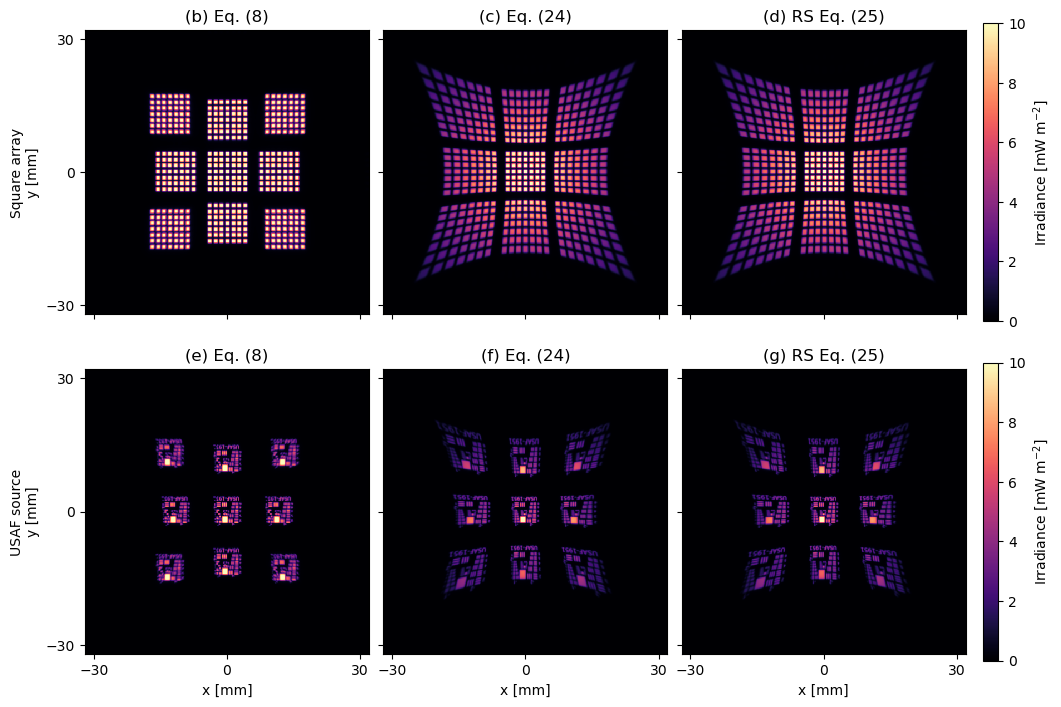

In [11]:
# Fig. 5(b–g): display both sources on one absolute irradiance scale.
fig5_images = np.asarray([[fig5_square_8, fig5_square_24, fig5_square_rs],
                         [fig5_usaf_8, fig5_usaf_24, fig5_usaf_rs]])
fig5_figure, fig5_axes = plt.subplots(2, 3, figsize=(10.5, 7),
    layout="constrained", sharex=True, sharey=True)
fig5_titles = [["(b) Eq. (8)", "(c) Eq. (24)", "(d) RS Eq. (25)"],
               ["(e) Eq. (8)", "(f) Eq. (24)", "(g) RS Eq. (25)"]]
fig5_step = float(fig5_x[1]-fig5_x[0])
fig5_extent = np.asarray([-fig5_halfwidth-fig5_step/2,
                          fig5_halfwidth+fig5_step/2]*2)/mm
for row in range(2):
    for col in range(3):
        ax = fig5_axes[row, col]
        im = ax.imshow(fig5_images[row, col]/1e-3, origin="lower",
            extent=fig5_extent, cmap="magma", vmin=0, vmax=10,
            interpolation="nearest")
        ax.set(title=fig5_titles[row][col], aspect="equal",
            xlim=(-fig5_halfwidth/mm, fig5_halfwidth/mm),
            ylim=(-fig5_halfwidth/mm, fig5_halfwidth/mm),
            xticks=[-30, 0, 30], yticks=[-30, 0, 30])
        if row == 1:
            ax.set_xlabel("x [mm]")
        if col == 0:
            ax.set_ylabel(("Square array" if row == 0 else "USAF source")+"\ny [mm]")
    fig5_figure.colorbar(im, ax=fig5_axes[row, :], shrink=0.9, pad=0.02,
        label=r"Irradiance [mW m$^{-2}$]")
plt.show()

### Quantify the agreement and off-axis fall-off

We compare each image with RS on its absolute scale using
$\varepsilon=\|E-E_{\mathrm{RS}}\|_2/\|E_{\mathrm{RS}}\|_2$.
For the square array, we also sample corresponding bright squares in a side and a diagonal order. Their decrease in brightness is measured from the inner to the outer feature, as in Supplement S5.2.

We report Eq. (24)–RS errors of $0.046\%$ for the square array and $0.031\%$ for the USAF source, with about $44\%$/$79\%$ side/diagonal fall-off. The values below are calculated from this run. For a convergence check, increase one sampling setting or RS interpolation order at a time and rerun the comparison cells.

In [12]:
# Compare absolute irradiance and registered bright-feature values.
from scipy.ndimage import map_coordinates

for label, images in zip(("Square array", "USAF source"), fig5_images):
    reference = images[2]
    errors = [100*np.linalg.norm(image-reference)/np.linalg.norm(reference)
              for image in images[:2]]
    print(f"{label}: Eq. (8)–RS = {errors[0]:.4f}% | Eq. (24)–RS = {errors[1]:.4f}%")

fig5_source_centres = (np.arange(source_count)-(source_count-1)/2)*source_pitch
for label, order in (("Side", (1, 0)), ("Diagonal", (1, 1))):
    points = fig5_source_centres[:, None]*np.asarray(order)
    incident = points/np.sqrt(z1**2+(points**2).sum(axis=1))[:, None]
    outgoing = wavelength/period*np.asarray(order)-incident
    positions = z2*outgoing/np.sqrt(1-(outgoing**2).sum(axis=1))[:, None]
    coordinates = np.array([(positions[:, 1]-float(fig5_y[0]))/fig5_step,
                            (positions[:, 0]-float(fig5_x[0]))/fig5_step])
    values = map_coordinates(np.asarray(fig5_square_rs), coordinates, order=3)
    falloff = 100*(1-values[0]/values[-1])
    print(f"{label} order: inner-to-outer bright-feature fall-off = {falloff:.2f}%")

Square array: Eq. (8)–RS = 97.0416% | Eq. (24)–RS = 0.9447%
USAF source: Eq. (8)–RS = 91.2278% | Eq. (24)–RS = 1.5279%
Side order: inner-to-outer bright-feature fall-off = 44.27%
Diagonal order: inner-to-outer bright-feature fall-off = 78.75%
